# Continuous State Discretization using VQ-VAE & Action Masking Analysis (Acrobot-v1, DQN)

This notebook demonstrates:
1. **Environment Setup & Data Collection**: Sampling continuous-state / **discrete-action** trajectories from the Gymnasium `Acrobot-v1` environment (6-D state: $\cos\theta_1, \sin\theta_1, \cos\theta_2, \sin\theta_2, \dot\theta_1, \dot\theta_2$; 3 discrete torques $a \in \{0, 1, 2\} \leftrightarrow \{-1, 0, +1\}$).
2. **DQN Agent**: Training (or loading) a Deep Q-Network and using its $\epsilon$-greedy policy to fill a replay buffer that reflects on-policy state visitation.
3. **VQ-VAE Architecture**: Discretizing the continuous state vector $s \in \mathbb{R}^6$ into a discrete codebook index $k \in \{0, \dots, K-1\}$.
4. **Training & Codebook Evaluation**: Training the VQ-VAE to minimize reconstruction error while monitoring codebook utilization/perplexity.
5. **Visualization**: Plotting the state-space partitioning (PCA projection and the physical phase space $\theta_1$ vs. $\dot\theta_1$) colored by discrete cluster assignment.
6. **Action Masking for State Retention**: Because the action space is finite, the mask $M(k, a) = P\big(z(s_{t+1}) = k \mid z(s_t) = k, a_t = a\big)$ is a dense $K \times 3$ table that can be estimated directly from transition counts and validated with a held-out precision check.


### Cell 1: Imports & Setup

In [1]:
import os
import copy
import random
from collections import deque

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


### Cell 2: Acrobot-v1 Environment Initialization & Random-Policy Trajectory Dataset Collection

In [2]:
# Initialize Acrobot-v1: continuous 6-D observation, discrete 3-way action space
ENV_NAME = 'Acrobot-v1'

env = gym.make(ENV_NAME)
print(f"Successfully initialized Gymnasium environment: {ENV_NAME}")

state_space = env.observation_space
action_space = env.action_space
assert isinstance(action_space, gym.spaces.Discrete), "This notebook assumes a Discrete action space (DQN)."

state_dim = state_space.shape[0]        # 6 for Acrobot-v1
n_actions = action_space.n              # 3 for Acrobot-v1
ACTION_LABELS = {0: 'torque -1', 1: 'torque 0', 2: 'torque +1'}
OBS_LABELS = ['cos θ1', 'sin θ1', 'cos θ2', 'sin θ2', 'θ̇1', 'θ̇2']

print(f"State Space : {state_space}")
print(f"Action Space: {action_space} -> {ACTION_LABELS}")
print(f"state_dim = {state_dim}, n_actions = {n_actions}")


Successfully initialized Gymnasium environment: Acrobot-v1
State Space : Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
Action Space: Discrete(3) -> {0: 'torque -1', 1: 'torque 0', 2: 'torque +1'}
state_dim = 6, n_actions = 3


In [3]:
# Collect trajectory samples (states, actions, next_states) with a uniform random policy.
# This is a quick baseline dataset; the DQN-driven replay buffer below replaces it.
NUM_SAMPLES = 25000
states = []
actions = []
next_states = []

obs, _ = env.reset(seed=SEED)
for _ in range(NUM_SAMPLES):
    action = env.action_space.sample()            # int in {0, 1, 2}
    next_obs, reward, terminated, truncated, _ = env.step(action)

    states.append(obs)
    actions.append(action)
    next_states.append(next_obs)

    if terminated or truncated:
        obs, _ = env.reset()
    else:
        obs = next_obs

states_np = np.array(states, dtype=np.float32)
actions_np = np.array(actions, dtype=np.int64)    # discrete action indices, shape (N,)

# Compute normalization stats for state space
state_mean = torch.tensor(states_np.mean(axis=0), dtype=torch.float32)
state_std = torch.tensor(states_np.std(axis=0) + 1e-6, dtype=torch.float32)

states_tensor = torch.tensor(states_np, dtype=torch.float32)
states_normalized = (states_tensor - state_mean) / state_std

dataset = TensorDataset(states_normalized)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)

print(f"Dataset collected (random policy): {len(states_tensor)} samples.")
print(f"Action counts: {dict(zip(*np.unique(actions_np, return_counts=True)))}")
print(f"State Means: {state_mean.numpy()}")
print(f"State Stds:  {state_std.numpy()}")


Dataset collected (random policy): 25000 samples.
Action counts: {np.int64(0): np.int64(8391), np.int64(1): np.int64(8229), np.int64(2): np.int64(8380)}
State Means: [8.9125037e-01 1.8628937e-04 6.7985821e-01 6.0495140e-04 2.5418955e-03
 2.8086356e-03]
State Stds:  [0.17402068 0.41880912 0.42039517 0.6008839  1.1829973  1.9789649 ]


No checkpoint found at 'dqn_acrobot_v1.pt' - training DQN for 100,000 steps ...
  step  10,000 | eps 0.250 | mean return (last 20 eps):   -394.4
  step  20,000 | eps 0.100 | mean return (last 20 eps):   -128.3
  step  30,000 | eps 0.100 | mean return (last 20 eps):   -128.8
  step  40,000 | eps 0.100 | mean return (last 20 eps):   -112.0
  step  50,000 | eps 0.100 | mean return (last 20 eps):   -107.7
  step  60,000 | eps 0.100 | mean return (last 20 eps):   -103.8
  step  70,000 | eps 0.100 | mean return (last 20 eps):   -106.9
  step  80,000 | eps 0.100 | mean return (last 20 eps):    -91.0
  step  90,000 | eps 0.100 | mean return (last 20 eps):    -87.6
  step 100,000 | eps 0.100 | mean return (last 20 eps):    -85.5
Saved DQN weights to 'dqn_acrobot_v1.pt'.


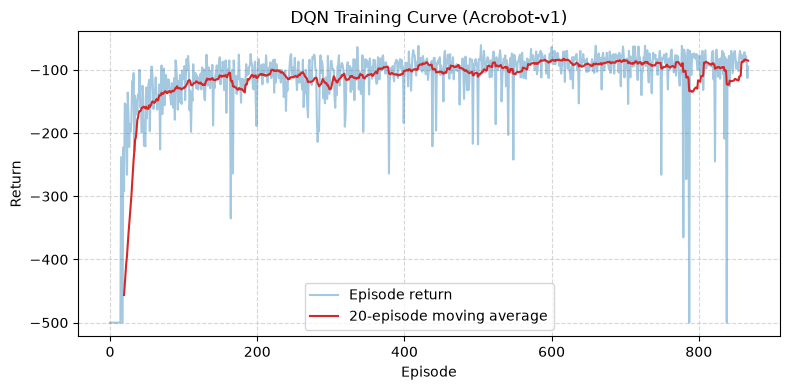

Dataset collected with DQN policy: 200000 samples.
Action counts: {np.int64(0): np.int64(98756), np.int64(1): np.int64(12641), np.int64(2): np.int64(88603)}
State Means: [ 0.528753    0.00223124  0.21118812  0.00122229  0.03089718 -0.20926523]
State Stds:  [0.5265765  0.66569525 0.6885167  0.6937723  2.3706408  3.761585  ]


In [4]:
# ---------------------------------------------------------
# Define Q-Network Architecture (DQN) for the discrete Acrobot action space
# ---------------------------------------------------------
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, state):
        return self.net(state)                     # Q(s, ·) for every discrete action

    def get_action(self, state, epsilon=0.0):
        # ε-greedy action selection; `state` is a (1, state_dim) tensor
        if random.random() < epsilon:
            return random.randrange(self.net[-1].out_features)
        with torch.no_grad():
            return int(self.forward(state).argmax(dim=1).item())


class ReplayBuffer:
    def __init__(self, capacity):
        self.buf = deque(maxlen=capacity)

    def push(self, s, a, r, s2, done):
        self.buf.append((s, a, r, s2, done))

    def sample(self, batch_size):
        batch = random.sample(self.buf, batch_size)
        s, a, r, s2, d = map(np.array, zip(*batch))
        return (torch.tensor(s, dtype=torch.float32, device=device),
                torch.tensor(a, dtype=torch.int64, device=device),
                torch.tensor(r, dtype=torch.float32, device=device),
                torch.tensor(s2, dtype=torch.float32, device=device),
                torch.tensor(d, dtype=torch.float32, device=device))

    def __len__(self):
        return len(self.buf)


# ---------------------------------------------------------
# DQN hyper-parameters (close to the rl-zoo Acrobot-v1 defaults)
# ---------------------------------------------------------
CHECKPOINT_PATH   = 'dqn_acrobot_v1.pt'   # if this file exists, training is skipped and weights are loaded
TRAIN_STEPS       = 100_000
BUFFER_SIZE       = 50_000
BATCH_SIZE        = 128
GAMMA             = 0.99
LR                = 6.3e-4
LEARNING_STARTS   = 1_000
TRAIN_FREQ        = 4
TARGET_UPDATE     = 250
EPS_START, EPS_END = 1.0, 0.10
EPS_DECAY_STEPS   = int(0.12 * TRAIN_STEPS)

policy = QNetwork(state_dim, n_actions).to(device)

if os.path.exists(CHECKPOINT_PATH):
    policy.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))
    print(f"Loaded pretrained DQN weights from '{CHECKPOINT_PATH}' - skipping training.")
else:
    print(f"No checkpoint found at '{CHECKPOINT_PATH}' - training DQN for {TRAIN_STEPS:,} steps ...")
    target_net = copy.deepcopy(policy).to(device)
    target_net.eval()
    optimizer_dqn = torch.optim.Adam(policy.parameters(), lr=LR)
    buffer = ReplayBuffer(BUFFER_SIZE)

    episode_returns, ep_return = [], 0.0
    obs, _ = env.reset(seed=SEED)
    for step in range(1, TRAIN_STEPS + 1):
        eps = max(EPS_END, EPS_START - (EPS_START - EPS_END) * step / EPS_DECAY_STEPS)
        obs_t = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)
        action = policy.get_action(obs_t, epsilon=eps)

        next_obs, reward, terminated, truncated, _ = env.step(action)
        buffer.push(obs, action, reward, next_obs, float(terminated))   # bootstrap through truncation
        ep_return += reward

        if terminated or truncated:
            episode_returns.append(ep_return)
            ep_return = 0.0
            obs, _ = env.reset()
        else:
            obs = next_obs

        if step >= LEARNING_STARTS and step % TRAIN_FREQ == 0 and len(buffer) >= BATCH_SIZE:
            s, a, r, s2, d = buffer.sample(BATCH_SIZE)
            q_sa = policy(s).gather(1, a.unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                q_next = target_net(s2).max(dim=1).values
                target = r + GAMMA * (1.0 - d) * q_next
            loss_dqn = F.smooth_l1_loss(q_sa, target)
            optimizer_dqn.zero_grad()
            loss_dqn.backward()
            nn.utils.clip_grad_norm_(policy.parameters(), 10.0)
            optimizer_dqn.step()

        if step % TARGET_UPDATE == 0:
            target_net.load_state_dict(policy.state_dict())

        if step % 10_000 == 0:
            recent = np.mean(episode_returns[-20:]) if episode_returns else float('nan')
            print(f"  step {step:7,d} | eps {eps:.3f} | mean return (last 20 eps): {recent:8.1f}")

    torch.save(policy.state_dict(), CHECKPOINT_PATH)
    print(f"Saved DQN weights to '{CHECKPOINT_PATH}'.")

    plt.figure(figsize=(8, 4))
    plt.plot(episode_returns, alpha=0.4, label='Episode return')
    if len(episode_returns) >= 20:
        smooth = np.convolve(episode_returns, np.ones(20) / 20, mode='valid')
        plt.plot(np.arange(19, len(episode_returns)), smooth, label='20-episode moving average', color='tab:red')
    plt.xlabel('Episode'); plt.ylabel('Return'); plt.title(f'DQN Training Curve ({ENV_NAME})')
    plt.grid(True, linestyle='--', alpha=0.5); plt.legend(); plt.tight_layout(); plt.show()

policy.eval()

# ---------------------------------------------------------
# Collect trajectory samples from the trained DQN agent (ε-greedy with small ε
# so the buffer covers all three actions in every region of state space)
# ---------------------------------------------------------
NUM_SAMPLES = 200000
COLLECT_EPS = 0.05
states = []
actions = []
next_states = []

obs, _ = env.reset(seed=SEED)
for step in range(NUM_SAMPLES):
    obs_tensor = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)
    action = policy.get_action(obs_tensor, epsilon=COLLECT_EPS)

    next_obs, reward, terminated, truncated, _ = env.step(action)

    states.append(obs)
    actions.append(action)
    next_states.append(next_obs)

    if terminated or truncated:
        obs, _ = env.reset()
    else:
        obs = next_obs

states_np = np.array(states, dtype=np.float32)
actions_np = np.array(actions, dtype=np.int64)                 # (N,) discrete action indices
actions_oh = np.eye(n_actions, dtype=np.float32)[actions_np]    # (N, n_actions) one-hot, for feature-based tools
next_states_np = np.array(next_states, dtype=np.float32)

# Compute normalization stats for state space
state_mean = torch.tensor(states_np.mean(axis=0), dtype=torch.float32)
state_std = torch.tensor(states_np.std(axis=0) + 1e-6, dtype=torch.float32)

states_tensor = torch.tensor(states_np, dtype=torch.float32)
states_normalized = (states_tensor - state_mean) / state_std

dataset = TensorDataset(states_normalized)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)

print(f"Dataset collected with DQN policy: {len(states_tensor)} samples.")
print(f"Action counts: {dict(zip(*np.unique(actions_np, return_counts=True)))}")
print(f"State Means: {state_mean.numpy()}")
print(f"State Stds:  {state_std.numpy()}")


### Cell 3: VQ-VAE Architecture for State Space Discretization

In [5]:
class VectorQuantizer(nn.Module):
    """
    Vector Quantization Layer mapping continuous embeddings to discrete codebook vectors.
    """
    def __init__(self, num_embeddings=32, embedding_dim=16, commitment_cost=0.25):
        super(VectorQuantizer, self).__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost
        
        # Codebook storage
        self.embedding = nn.Embedding(self.num_embeddings, self.embedding_dim)
        self.embedding.weight.data.uniform_(-1.0 / self.num_embeddings, 1.0 / self.num_embeddings)
        
    def forward(self, inputs):
        # inputs shape: (batch_size, embedding_dim)
        # Calculate Euclidean distances between inputs and codebook embeddings
        distances = (torch.sum(inputs**2, dim=1, keepdim=True) 
                     + torch.sum(self.embedding.weight**2, dim=1)
                     - 2 * torch.matmul(inputs, self.embedding.weight.t()))
            
        # Find closest codebook indices
        encoding_indices = torch.argmin(distances, dim=1)
        quantized = self.embedding(encoding_indices)
        
        # VQ Losses
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)  # Vector quantization loss
        q_latent_loss = F.mse_loss(quantized, inputs.detach())  # Commitment loss
        loss = q_latent_loss + self.commitment_cost * e_latent_loss
        
        # Straight-Through Estimator (STE)
        quantized = inputs + (quantized - inputs).detach()
        
        # Compute Codebook Perplexity (utilization metric)
        encodings = F.one_hot(encoding_indices, self.num_embeddings).float()
        avg_probs = torch.mean(encodings, dim=0)
        perplexity = torch.exp(-torch.sum(avg_probs * torch.log(avg_probs + 1e-10)))
        
        return quantized, loss, encoding_indices, perplexity

class VQVAEStateDiscretizer(nn.Module):
    """
    VQ-VAE Architecture for discretizing continuous state spaces.
    """
    def __init__(self, state_dim, hidden_dim=64, embedding_dim=16, num_embeddings=32, commitment_cost=0.25):
        super(VQVAEStateDiscretizer, self).__init__()
        
        # Continuous State Encoder
        self.encoder = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        
        # Vector Quantizer Codebook
        self.vq_layer = VectorQuantizer(num_embeddings, embedding_dim, commitment_cost)
        
        # Continuous State Decoder
        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, state_dim)
        )
        
    def forward(self, state):
        z_e = self.encoder(state)
        z_q, vq_loss, encoding_indices, perplexity = self.vq_layer(z_e)
        state_recon = self.decoder(z_q)
        return state_recon, vq_loss, encoding_indices, perplexity

    def encode_to_discrete(self, state):
        z_e = self.encoder(state)
        _, _, encoding_indices, _ = self.vq_layer(z_e)
        return encoding_indices

# Instantiate Model
NUM_EMBEDDINGS = 256   # Number of discrete states (clusters)
EMBEDDING_DIM = 4  # Dimension of codebook vectors

state_dim = states_np.shape[1]   # 6 for Acrobot-v1

vqvae_model = VQVAEStateDiscretizer(
    state_dim=state_dim,
    hidden_dim=64,
    embedding_dim=EMBEDDING_DIM,
    num_embeddings=NUM_EMBEDDINGS,
    commitment_cost=0.25
).to(device)

print(vqvae_model)

VQVAEStateDiscretizer(
  (encoder): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
  (vq_layer): VectorQuantizer(
    (embedding): Embedding(256, 4)
  )
  (decoder): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=6, bias=True)
  )
)


### Cell 4: Training VQ-VAE State Discretizer

Epoch [01/50] | Total Loss: 3.87257 | Recon MSE: 0.55174 | VQ Loss: 3.32083 | Codebook Perplexity: 5.83/256
Epoch [05/50] | Total Loss: 0.80970 | Recon MSE: 0.23930 | VQ Loss: 0.57040 | Codebook Perplexity: 17.85/256
Epoch [10/50] | Total Loss: 0.57401 | Recon MSE: 0.15785 | VQ Loss: 0.41616 | Codebook Perplexity: 32.10/256
Epoch [15/50] | Total Loss: 0.51896 | Recon MSE: 0.13924 | VQ Loss: 0.37972 | Codebook Perplexity: 37.91/256
Epoch [20/50] | Total Loss: 0.47654 | Recon MSE: 0.12470 | VQ Loss: 0.35184 | Codebook Perplexity: 43.43/256
Epoch [25/50] | Total Loss: 0.44035 | Recon MSE: 0.11740 | VQ Loss: 0.32295 | Codebook Perplexity: 45.74/256
Epoch [30/50] | Total Loss: 0.43725 | Recon MSE: 0.11457 | VQ Loss: 0.32268 | Codebook Perplexity: 48.67/256
Epoch [35/50] | Total Loss: 0.41392 | Recon MSE: 0.10908 | VQ Loss: 0.30484 | Codebook Perplexity: 51.22/256
Epoch [40/50] | Total Loss: 0.39081 | Recon MSE: 0.10389 | VQ Loss: 0.28692 | Codebook Perplexity: 54.40/256
Epoch [45/50] | Tota

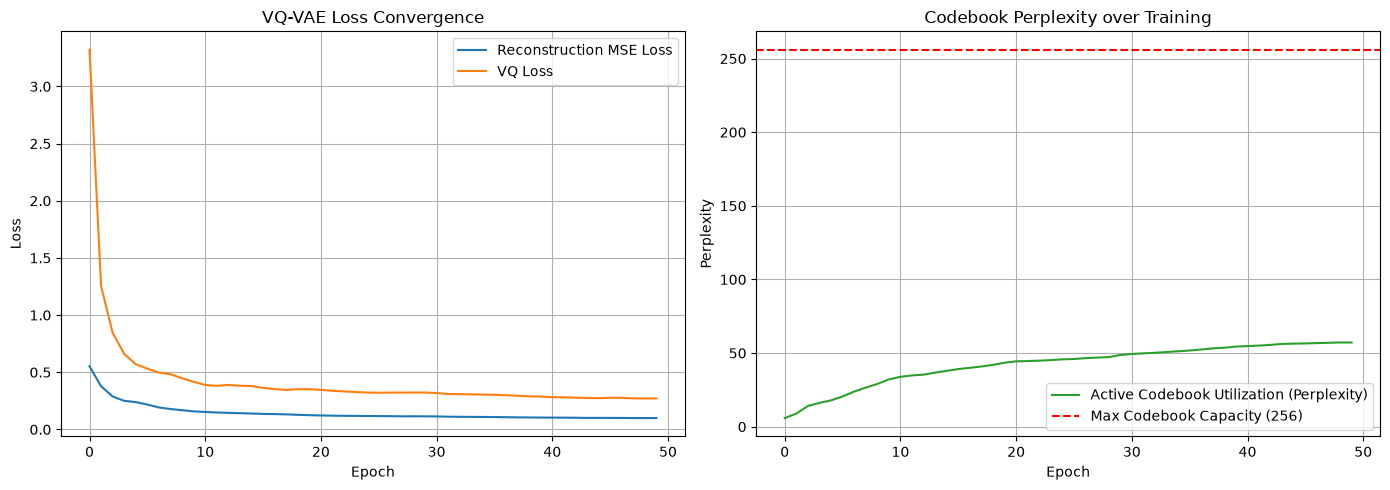

In [6]:
optimizer = torch.optim.Adam(vqvae_model.parameters(), lr=1e-3)
EPOCHS = 50

loss_history = []
recon_loss_history = []
vq_loss_history = []
perplexity_history = []

vqvae_model.train()
for epoch in range(1, EPOCHS + 1):
    total_loss_epoch = 0.0
    total_recon_epoch = 0.0
    total_vq_epoch = 0.0
    total_perp_epoch = 0.0
    
    for batch in dataloader:
        b_states = batch[0].to(device)
        
        optimizer.zero_grad()
        state_recon, vq_loss, _, perplexity = vqvae_model(b_states)
        
        recon_loss = F.mse_loss(state_recon, b_states)
        loss = recon_loss + vq_loss
        
        loss.backward()
        optimizer.step()
        
        total_loss_epoch += loss.item()
        total_recon_epoch += recon_loss.item()
        total_vq_epoch += vq_loss.item()
        total_perp_epoch += perplexity.item()
        
    n_batches = len(dataloader)
    avg_loss = total_loss_epoch / n_batches
    avg_recon = total_recon_epoch / n_batches
    avg_vq = total_vq_epoch / n_batches
    avg_perp = total_perp_epoch / n_batches
    
    loss_history.append(avg_loss)
    recon_loss_history.append(avg_recon)
    vq_loss_history.append(avg_vq)
    perplexity_history.append(avg_perp)
    
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Total Loss: {avg_loss:.5f} | Recon MSE: {avg_recon:.5f} | VQ Loss: {avg_vq:.5f} | Codebook Perplexity: {avg_perp:.2f}/{NUM_EMBEDDINGS}")


# Plot Training Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(recon_loss_history, label='Reconstruction MSE Loss', color='tab:blue')
axes[0].plot(vq_loss_history, label='VQ Loss', color='tab:orange')
axes[0].set_title('VQ-VAE Loss Convergence')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(perplexity_history, label='Active Codebook Utilization (Perplexity)', color='tab:green')
axes[1].axhline(y=NUM_EMBEDDINGS, color='r', linestyle='--', label=f'Max Codebook Capacity ({NUM_EMBEDDINGS})')
axes[1].set_title('Codebook Perplexity over Training')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Perplexity')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

### Cell 5: Visualizing Continuous State Space Discretization (PCA Projection & Acrobot Phase Space)

Unique discrete state clusters used: 102 out of 256


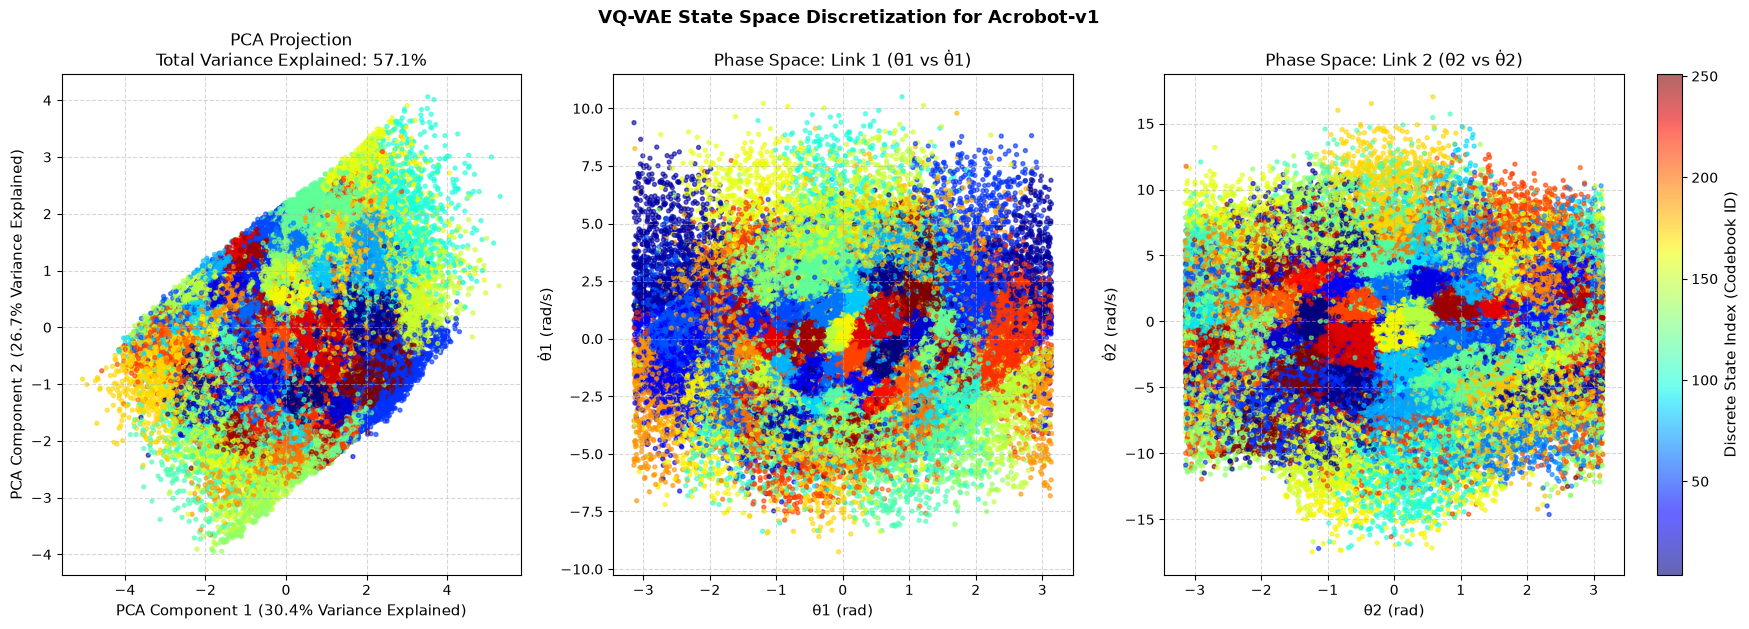

In [7]:
vqvae_model.eval()
with torch.no_grad():
    states_norm_dev = states_normalized.to(device)
    discrete_indices = vqvae_model.encode_to_discrete(states_norm_dev).cpu().numpy()

print(f"Unique discrete state clusters used: {len(np.unique(discrete_indices))} out of {NUM_EMBEDDINGS}")

# ---------------------------------------------------------
# PCA Projection for State Space Visualization
# ---------------------------------------------------------
# Standardize data prior to PCA
states_mean = np.mean(states_np, axis=0)
states_std = np.std(states_np, axis=0)
states_std[states_std == 0] = 1.0  # Prevent division by zero
states_centered = (states_np - states_mean) / states_std

# Compute PCA via Singular Value Decomposition (SVD)
U, S, Vt = np.linalg.svd(states_centered, full_matrices=False)
pca_states = states_centered @ Vt[:2].T  # Project onto top 2 Principal Components

# Calculate percentage of variance explained
explained_variance = (S**2) / (len(states_np) - 1)
total_variance = np.sum(explained_variance)
var_exp = (explained_variance[:2] / total_variance) * 100

# ---------------------------------------------------------
# Physical phase-space coordinates of Acrobot (recover angles from cos/sin)
# ---------------------------------------------------------
theta1 = np.arctan2(states_np[:, 1], states_np[:, 0])   # link-1 angle
theta2 = np.arctan2(states_np[:, 3], states_np[:, 2])   # link-2 angle (relative)
dtheta1 = states_np[:, 4]
dtheta2 = states_np[:, 5]

# ---------------------------------------------------------
# Plotting
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

sc0 = axes[0].scatter(pca_states[:, 0], pca_states[:, 1], c=discrete_indices, cmap='jet', alpha=0.6, s=8)
axes[0].set_xlabel(f'PCA Component 1 ({var_exp[0]:.1f}% Variance Explained)', fontsize=11)
axes[0].set_ylabel(f'PCA Component 2 ({var_exp[1]:.1f}% Variance Explained)', fontsize=11)
axes[0].set_title(f'PCA Projection\nTotal Variance Explained: {sum(var_exp[:2]):.1f}%', fontsize=12)

sc1 = axes[1].scatter(theta1, dtheta1, c=discrete_indices, cmap='jet', alpha=0.6, s=8)
axes[1].set_xlabel('θ1 (rad)', fontsize=11)
axes[1].set_ylabel('θ̇1 (rad/s)', fontsize=11)
axes[1].set_title('Phase Space: Link 1 (θ1 vs θ̇1)', fontsize=12)

sc2 = axes[2].scatter(theta2, dtheta2, c=discrete_indices, cmap='jet', alpha=0.6, s=8)
axes[2].set_xlabel('θ2 (rad)', fontsize=11)
axes[2].set_ylabel('θ̇2 (rad/s)', fontsize=11)
axes[2].set_title('Phase Space: Link 2 (θ2 vs θ̇2)', fontsize=12)

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)

cbar = fig.colorbar(sc2, ax=axes, fraction=0.02, pad=0.02)
cbar.set_label('Discrete State Index (Codebook ID)', fontsize=11)

fig.suptitle(f'VQ-VAE State Space Discretization for {ENV_NAME}', fontsize=13, fontweight='bold')
plt.show()


### Cell 6: Action Masking Analysis to Maintain Discrete State (Self-Loop Actions)

REPLAY BUFFER DISCRETE TRANSITION ANALYSIS (Acrobot-v1)
Total Trajectory Transitions (s_t -> s_{t+1}): 200,000
Self-Loop Transitions (z(s_t) == z(s_{t+1})): 39,638 (19.82%)
State-Changing Transitions (z(s_t) != z(s_{t+1})): 160,362 (80.18%)


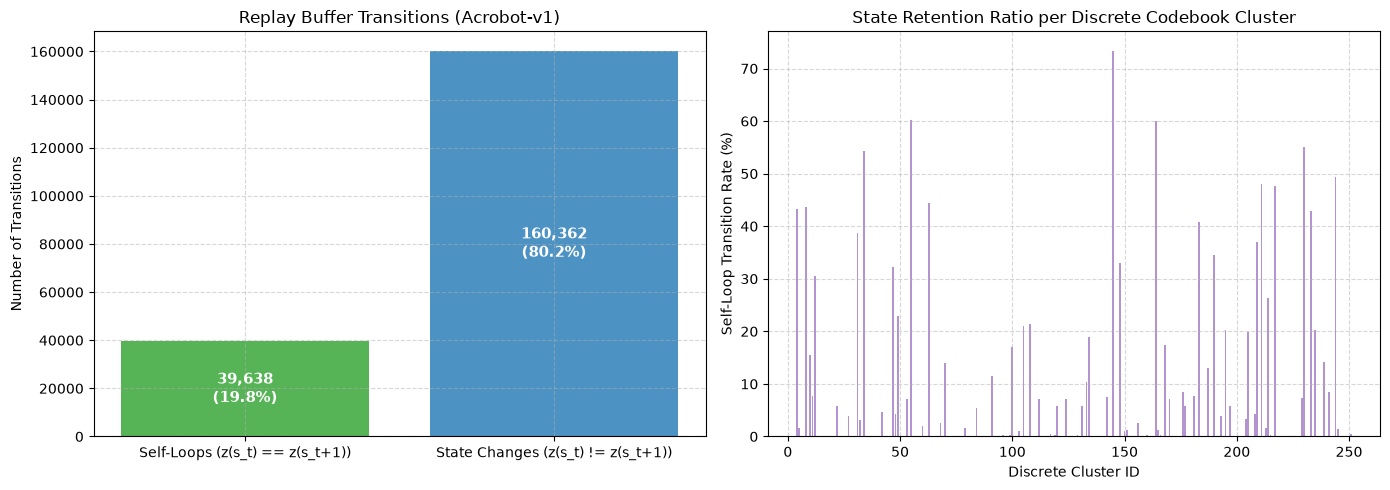

In [8]:
# ---------------------------------------------------------
# 1. Normalize Replay Buffer (states & next_states)
# ---------------------------------------------------------
states_tensor = torch.tensor(states_np, dtype=torch.float32)
next_states_tensor = torch.tensor(next_states_np, dtype=torch.float32)

# Normalize using dataset stats
states_norm = (states_tensor - state_mean) / state_std
next_states_norm = (next_states_tensor - state_mean) / state_std

# ---------------------------------------------------------
# 2. Encode Transitions (s_t -> z_t) and (s_{t+1} -> z_{t+1})
# ---------------------------------------------------------
vqvae_model.eval()
with torch.no_grad():
    states_disc = vqvae_model.encode_to_discrete(states_norm.to(device)).cpu().numpy()
    next_states_disc = vqvae_model.encode_to_discrete(next_states_norm.to(device)).cpu().numpy()

# ---------------------------------------------------------
# 3. Transition Breakdown Analysis
# ---------------------------------------------------------
total_transitions = len(states_disc)
is_self_loop = (states_disc == next_states_disc)

num_self_loops = np.sum(is_self_loop)
num_state_changes = total_transitions - num_self_loops

self_loop_pct = (num_self_loops / total_transitions) * 100
state_change_pct = (num_state_changes / total_transitions) * 100

print("="*60)
print(f"REPLAY BUFFER DISCRETE TRANSITION ANALYSIS ({ENV_NAME})")
print("="*60)
print(f"Total Trajectory Transitions (s_t -> s_{{t+1}}): {total_transitions:,}")
print(f"Self-Loop Transitions (z(s_t) == z(s_{{t+1}})): {num_self_loops:,} ({self_loop_pct:.2f}%)")
print(f"State-Changing Transitions (z(s_t) != z(s_{{t+1}})): {num_state_changes:,} ({state_change_pct:.2f}%)")
print("="*60)

# ---------------------------------------------------------
# 4. Cluster-level Self-Loop & Action Masking Statistics
# ---------------------------------------------------------
unique_clusters, cluster_counts = np.unique(states_disc, return_counts=True)

cluster_self_loop_counts = np.zeros(NUM_EMBEDDINGS, dtype=int)
cluster_total_counts = np.zeros(NUM_EMBEDDINGS, dtype=int)

for cluster_id in range(NUM_EMBEDDINGS):
    cluster_mask = (states_disc == cluster_id)
    cluster_total_counts[cluster_id] = np.sum(cluster_mask)
    if cluster_total_counts[cluster_id] > 0:
        cluster_self_loop_counts[cluster_id] = np.sum(is_self_loop[cluster_mask])

# Self-loop ratio per cluster (Action Masking potential)
active_clusters = cluster_total_counts > 0
self_loop_ratios = np.zeros(NUM_EMBEDDINGS)
self_loop_ratios[active_clusters] = (cluster_self_loop_counts[active_clusters] / cluster_total_counts[active_clusters]) * 100

# ---------------------------------------------------------
# 5. Diagnostic Plots
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Self-Loop vs State-Change Distribution
axes[0].bar(['Self-Loops (z(s_t) == z(s_t+1))', 'State Changes (z(s_t) != z(s_t+1))'], 
            [num_self_loops, num_state_changes], color=['tab:green', 'tab:blue'], alpha=0.8)
axes[0].set_ylabel('Number of Transitions')
axes[0].set_title(f'Replay Buffer Transitions ({ENV_NAME})')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Add counts on top of bars
for bar in axes[0].patches:
    axes[0].annotate(f"{int(bar.get_height()):,}\n({bar.get_height()/total_transitions*100:.1f}%)",
                     (bar.get_x() + bar.get_width() / 2, bar.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Plot 2: Per-Cluster Self-Loop Rate (Action Retention Density)
active_cluster_ids = np.where(active_clusters)[0]
axes[1].bar(active_cluster_ids, self_loop_ratios[active_cluster_ids], color='tab:purple', alpha=0.7)
axes[1].set_xlabel('Discrete Cluster ID')
axes[1].set_ylabel('Self-Loop Transition Rate (%)')
axes[1].set_title('State Retention Ratio per Discrete Codebook Cluster')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


CODEBOOK USAGE  (K = 256)
active codes            : 102 / 256
perplexity              : 70.2  (27% of K)
largest code share      : 5.18%   (uniform would be 0.39%)
top-10 codes share      : 29.8%
codes holding 50% data  : 22
codes holding 90% data  : 62
usage Gini              : 0.79   (0 uniform, 1 collapsed)


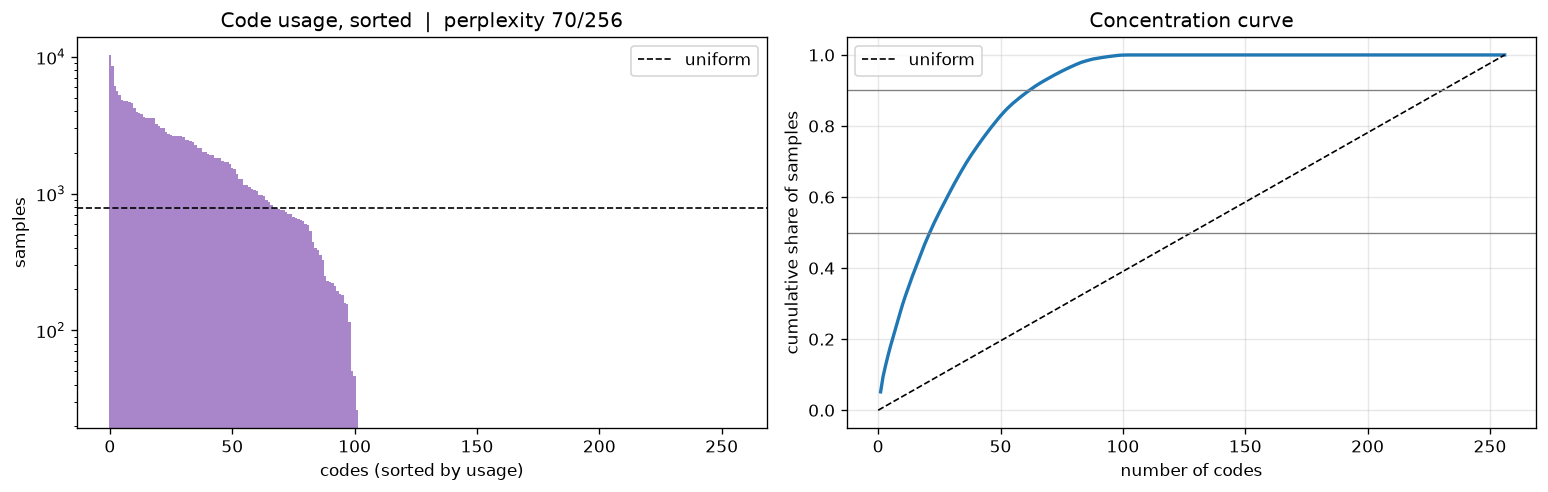

WITHIN-CELL SPREAD (RMS distance to cell centroid, normalized state units)
global RMS spread of data      : 2.450
median cell spread             : 0.869  (35% of global)  <- near 100% means codes ignore most state directions
sample-weighted mean spread    : 0.713
max cell spread (code, n)      : 1.581  (code 203, n=26)


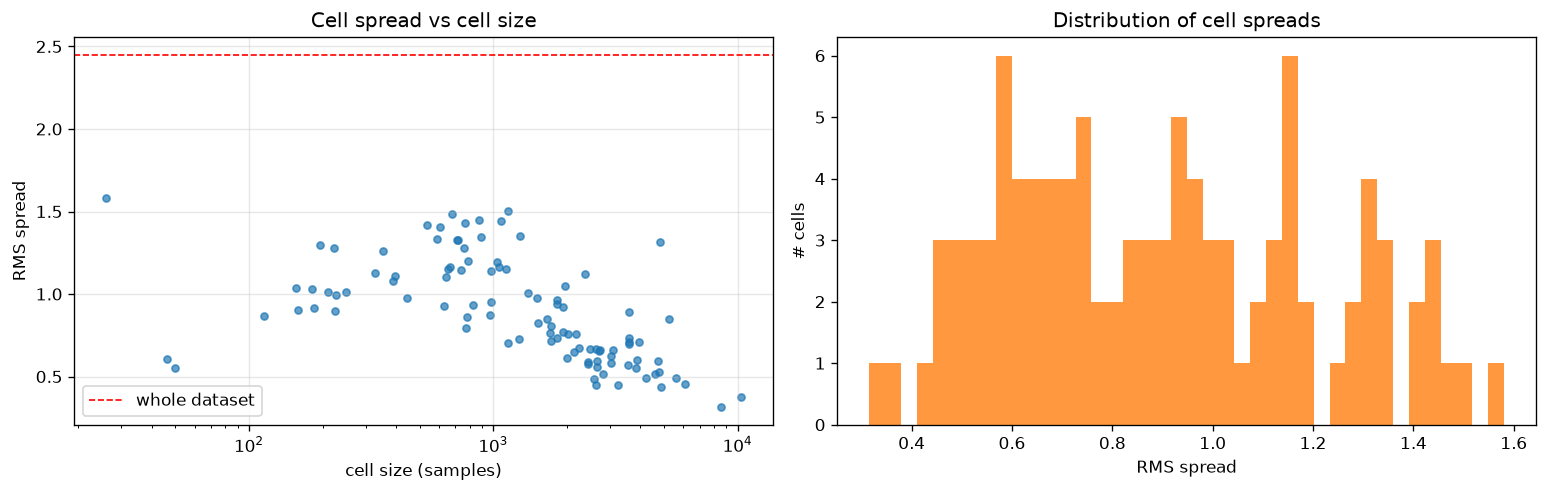

TRANSITION STRUCTURE
global self-loop rate           : 19.8%
median distinct successors/code : 14
codes with self-loop > 50%      : 5   (>80%: 0)


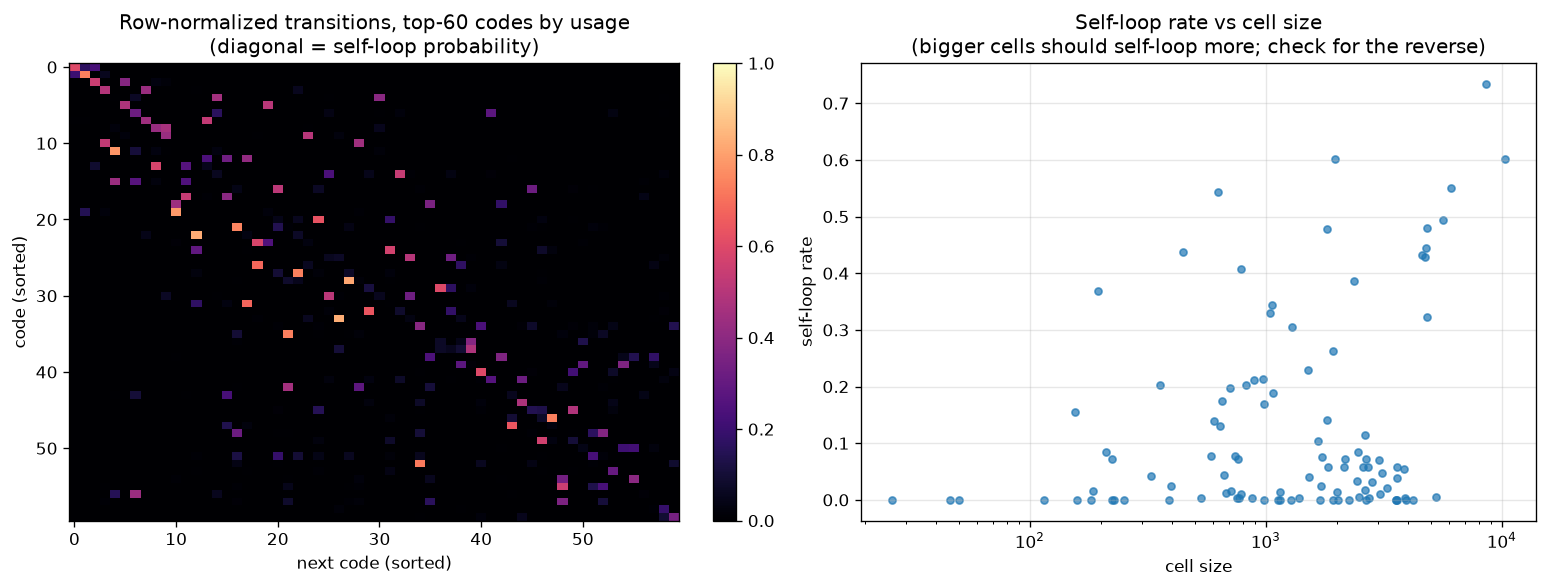

SEPARABILITY REPORT — action only (one-hot)  [gbm, 5-fold CV, features dim = 3]
cells evaluated                       : 100  (degenerate: 31)
sample-weighted AUROC                 : 0.584
sample-weighted balanced accuracy     : 0.593
sample-weighted MCC                   : 0.166
cells with AUROC >= 0.80               : 2
share of transitions in those cells   : 5.9%   <- this is your usable mask coverage
corr(precision, base rate)            : 0.93
corr(AUROC, base rate)                : 0.34


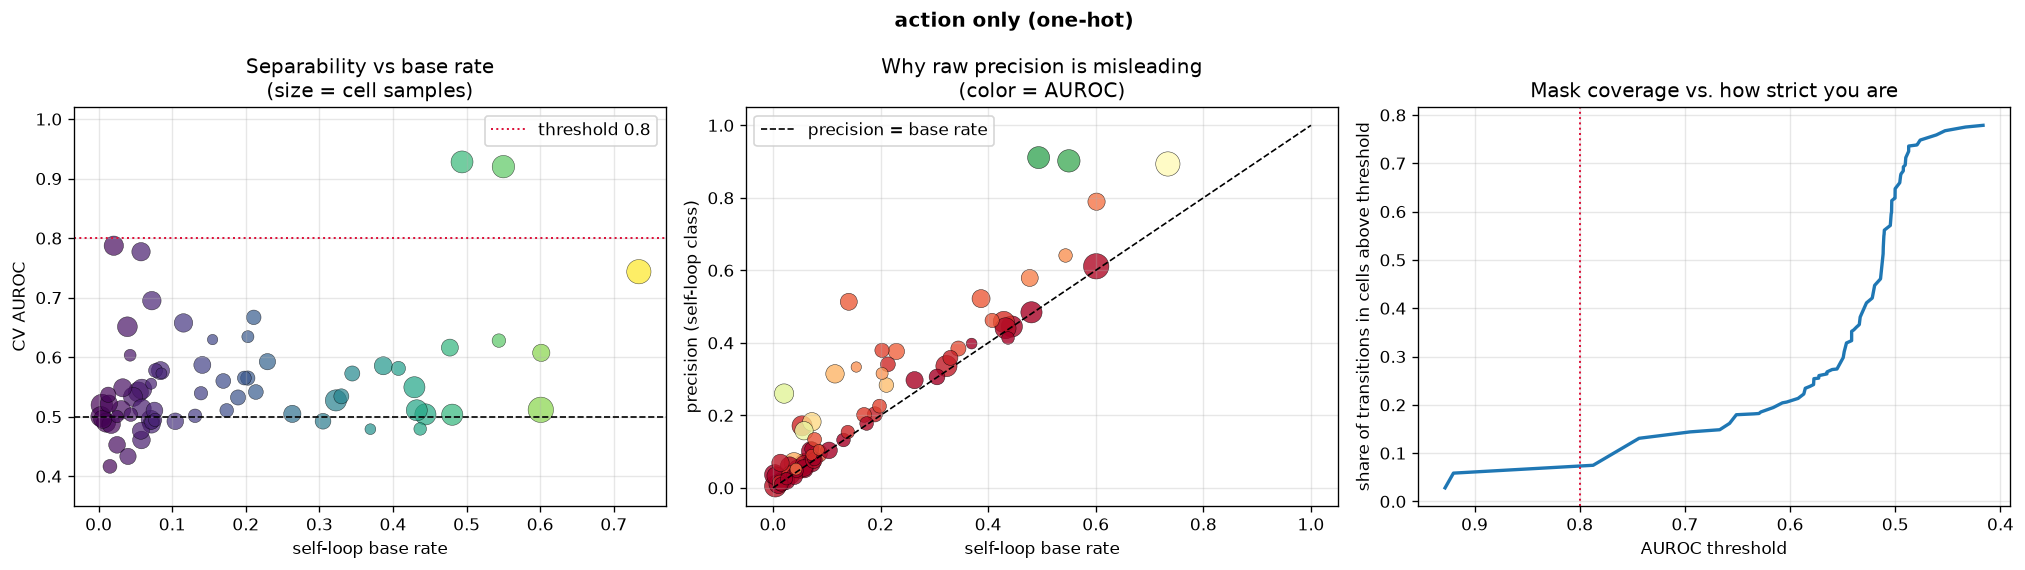

SEPARABILITY REPORT — action + position-in-cell  [gbm, 5-fold CV, features dim = 9]
cells evaluated                       : 100  (degenerate: 31)
sample-weighted AUROC                 : 0.983
sample-weighted balanced accuracy     : 0.930
sample-weighted MCC                   : 0.843
cells with AUROC >= 0.80               : 69
share of transitions in those cells   : 77.8%   <- this is your usable mask coverage
corr(precision, base rate)            : 0.61
corr(AUROC, base rate)                : 0.19


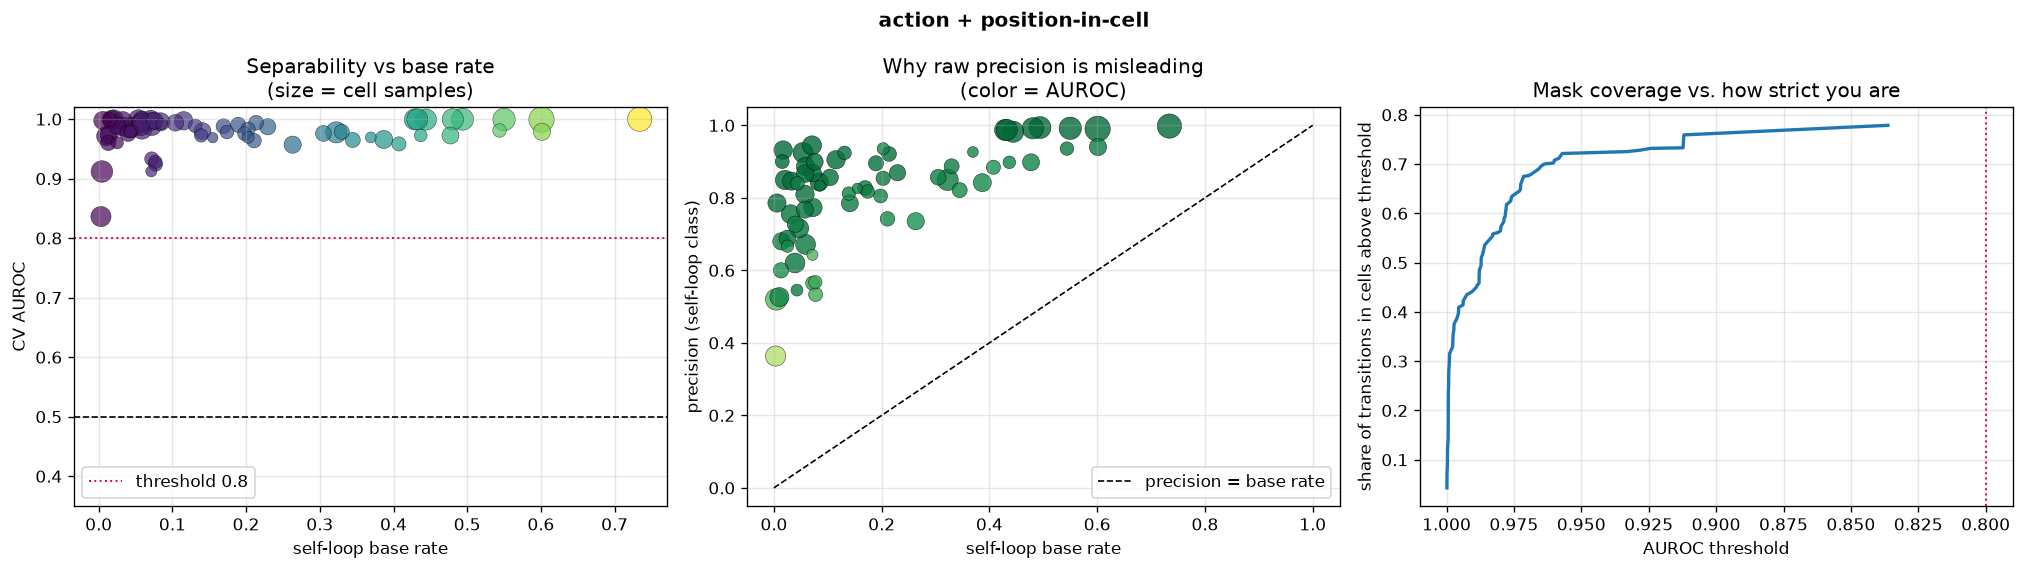

FEATURE-SET COMPARISON (sample-weighted AUROC)
action only                     : 0.584
action + position               : 0.983


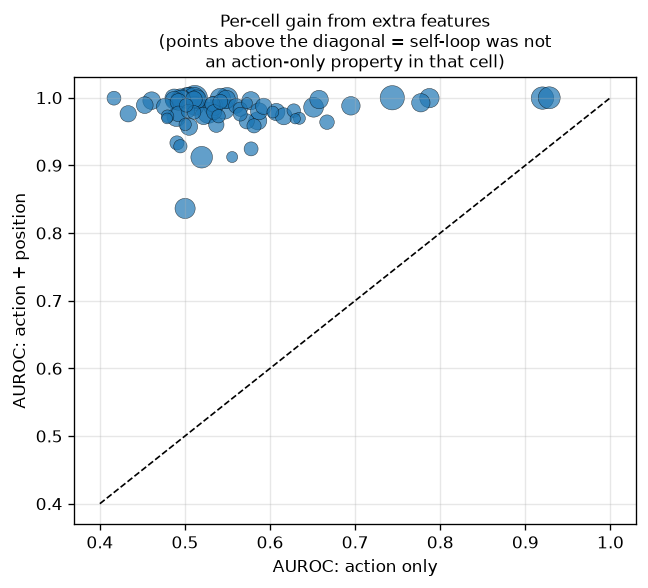

BOUNDARY-MARGIN vs ACTION-MAGNITUDE
variance of self-loop explained by margin deciles   : 3.4%
variance of self-loop explained by |a| deciles      : 0.0%
self-loop rate, closest-to-boundary decile -> deepest-in-cell decile: 13% -> 19%
self-loop rate, smallest |a| decile -> largest |a| decile           : nan% -> 20%


c:\Users\RijulTandon\OneDrive - ProcDNA Analytics Pvt. Ltd\Desktop\RL\Capabilities_In_Reinforcement_Learning\src\masking_diagnostics.py:407: RuntimeWarning: Mean of empty slice
  means = np.array([y[idx == b].mean() for b in range(bins)])
c:\Users\RijulTandon\OneDrive - ProcDNA Analytics Pvt. Ltd\Desktop\RL\venv_capabilities\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


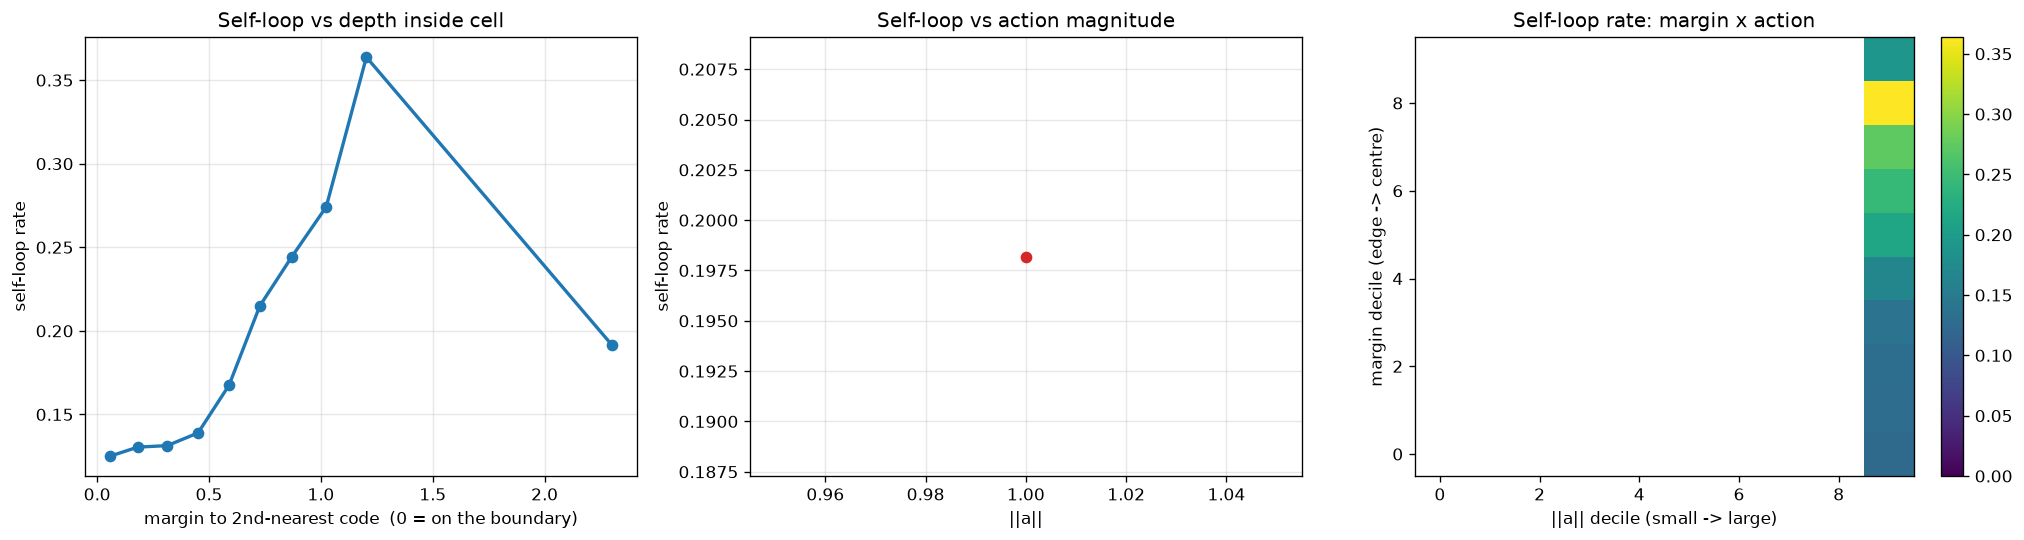

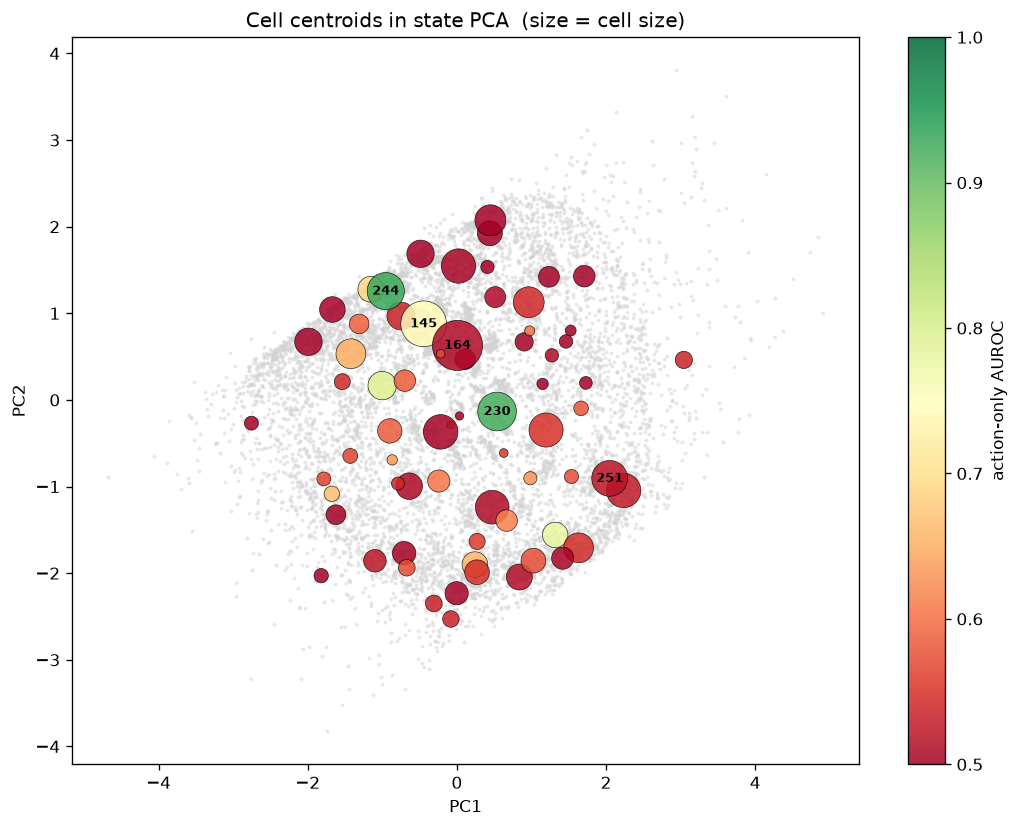

,code,n,pc1,pc2,pca_spread
0,0,0,NaN,NaN,NaN
1,1,0,NaN,NaN,NaN
2,2,0,NaN,NaN,NaN
3,3,0,NaN,NaN,NaN
4,4,4610,0.473046,-1.238603,0.376775
...,...,...,...,...,...
251,251,5238,2.048034,-0.905759,0.460909
252,252,0,NaN,NaN,NaN
253,253,0,NaN,NaN,NaN
254,254,0,NaN,NaN,NaN


In [10]:
# =============================================================================
# Snippets to paste into continuous_to_discrete_state.ipynb (after Cell 6).
# Requires masking_diagnostics.py next to the notebook.
# NOTE: these blocks use torch and your VQVAEStateDiscretizer; they follow
# your existing training cell exactly but were NOT executed in the sandbox
# that produced them (no torch there).  The numpy/sklearn module itself was.
#
# Acrobot has a Discrete(3) action space, so every call that expects a
# continuous (N, action_dim) action feature matrix receives the one-hot
# encoding `actions_oh` (N, 3) instead of a raw continuous vector.
# =============================================================================
import numpy as np, torch, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import masking_diagnostics as md

# --------------------------------------------------------------------------- #
# A. Run the diagnostics on the model you already have
# --------------------------------------------------------------------------- #
z_e, codebook = md.encoder_outputs(vqvae_model, states_norm, device)

md.codebook_usage_report(states_disc, NUM_EMBEDDINGS)
md.within_cluster_spread(states_norm.numpy(), states_disc, NUM_EMBEDDINGS)
md.transition_matrix_plot(states_disc, next_states_disc, NUM_EMBEDDINGS)

df_a  = md.separability_report(actions_oh, states_disc, is_self_loop, title="action only (one-hot)")
pos   = md.cell_position_features(z_e, codebook, states_disc)
df_ar = md.separability_report(actions_oh, states_disc, is_self_loop,
                               extra_features=pos, title="action + position-in-cell")
md.compare_reports({"action only": df_a, "action + position": df_ar})
md.boundary_margin_analysis(z_e, codebook, states_disc, is_self_loop, actions_oh)
md.pca_cells_plot(states_np, states_disc, sep_df=df_a, K=NUM_EMBEDDINGS)
